# CNN - Convolutional Neural Network

In [17]:
from itertools import count

import numpy as np
import pandas as pd
import os
from pathlib import Path

import cv2
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import kagglehub

import warnings
warnings.filterwarnings("ignore")

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

In [18]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia", output_dir='./datasets')

print("Path to dataset files:", path)

Path to dataset files: ./datasets


In [19]:
def check_data_structure(base_dir = './datasets/chest_xray'):
    base_path = Path(base_dir)
    if not base_path.exists():
        print(f'{base_path} does not exist')
        return False
    required_dirs = {
        'train':['NORMAL', 'PNEUMONIA'],
        'test':['NORMAL', 'PNEUMONIA'],
    }

    all_ok = True

    for split, classes in required_dirs.items():
        split_path = base_path / split
        if not split_path.exists():
            print(f'{split_path} does not exist')
            all_ok = False
            continue
        for class_name in classes:
            class_path = split_path / class_name
            if not class_path.exists():
                print(f'{class_path} does not exist')
                all_ok = False
            else:
                image_files = list(class_path.glob('*.jpg')) + list(class_path.glob('*.jpeg')) + list(class_path.glob('*.png'))
                count = len(image_files)

                if count == 0:
                    print(f'{class_path} has no images')
                else:
                    print(f'{class_path} has {count} images')
    return all_ok

check_data_structure()

datasets\chest_xray\train\NORMAL has 1341 images
datasets\chest_xray\train\PNEUMONIA has 3875 images
datasets\chest_xray\test\NORMAL has 234 images
datasets\chest_xray\test\PNEUMONIA has 390 images


True

In [20]:
IMG_SIZE = 224
IMG_CHANNELS = 3
BATCH_SIZE = 32
EPOCHS = 30
SEED = 42
VAL_SPLIT = .2

BASE_DIR = Path('./datasets/chest_xray')
DATA_DIR  = BASE_DIR / 'chest_xray'

TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'
VAL_DIR = DATA_DIR / 'val'

In [21]:
def count_images(directory):
    counts = {}
    if os.path.exists(directory):
            for class_name in os.listdir(directory):
                class_dir = os.path.join(directory, class_name)
                if os.path.isdir(class_dir):
                    image_files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                    count = len(image_files)
                    counts[class_name] = count
    return counts

Train set counts: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Class NORMAL has 1341 images
Class PNEUMONIA has 3875 images


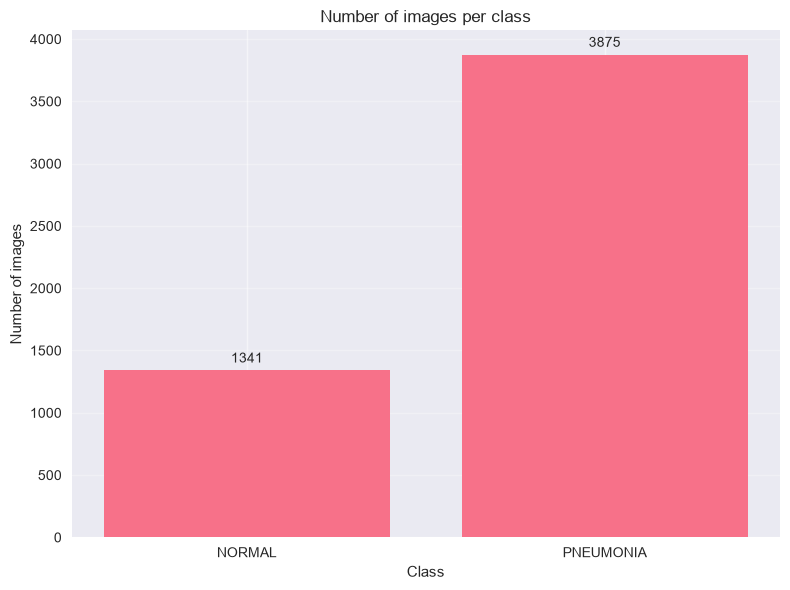

In [22]:
if os.path.exists(TRAIN_DIR):
    train_counts = count_images(TRAIN_DIR)
    print(f'Train set counts: {train_counts}')


    for class_name, count in train_counts.items():
        print(f'Class {class_name} has {count} images')

    plt.figure(figsize=(8, 6))
    classes = list(train_counts.keys())
    counts = list(train_counts.values())
    plt.bar(classes, counts)
    plt.xlabel('Class')
    plt.ylabel('Number of images')
    plt.grid(axis='y', alpha=0.3)
    plt.title('Number of images per class')

    for i, v in enumerate(counts):
        plt.text(i, v + max(counts)*0.01, str(v), ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Train set does not exist')

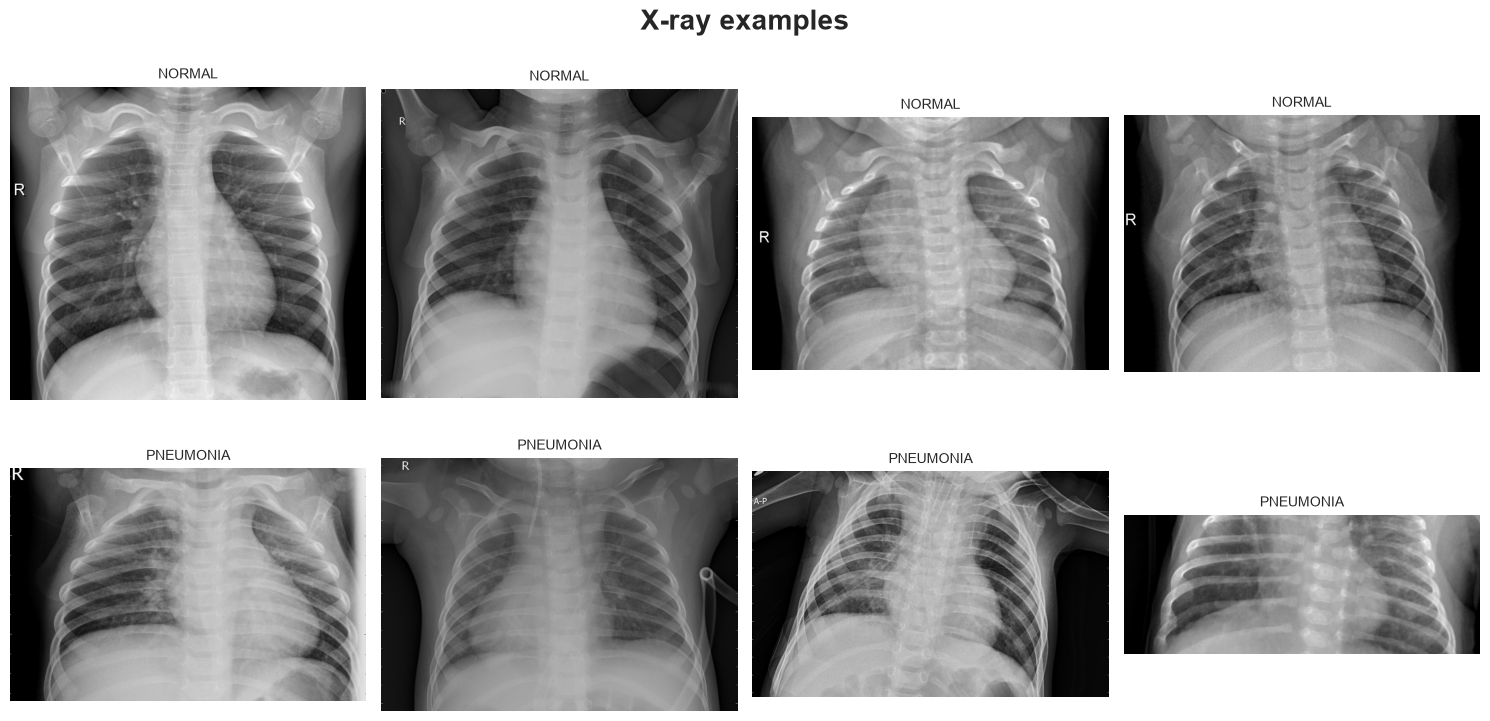

In [23]:
def visualize_samples(directory, num_samples=4):
    if not os.path.exists(directory):
        print(f'Directory {directory} does not exist')
        return

    fig, axes = plt.subplots(2, num_samples, figsize=(15, 8))
    fig.suptitle('X-ray examples', fontsize=20, fontweight='bold')


    classes = [d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))]

    for class_idx, class_name in enumerate(classes):
        class_dir = os.path.join(directory, class_name)
        image_files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        sample_files = np.random.choice(
            image_files,
            min(num_samples, len(image_files)),
            replace=False
        )

        for img_idx, img_file in enumerate(sample_files):
            img_path = os.path.join(class_dir, img_file)

            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            axes[class_idx, img_idx].imshow(img, cmap='gray')
            axes[class_idx, img_idx].set_title(class_name, fontsize=10)
            axes[class_idx, img_idx].axis('off')
    plt.tight_layout()
    plt.show()
if os.path.exists(TRAIN_DIR):
    visualize_samples(TRAIN_DIR)

# Data Augmentation

[Data augmentation](https://www.ibm.com/think/topics/data-augmentation)

In [24]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=70,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    validation_split= VAL_SPLIT,
    fill_mode='nearest',
)

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split= VAL_SPLIT,
)

test_datagen = ImageDataGenerator(
    rescale=1./255,
)


# Neyron şəbəbkənin arxitekturası

1. Conv2D
2. MaxPooling2D
3. Batch Normalization
4. Dropout
5. Dense

[CNN](https://en.wikipedia.org/wiki/Convolutional_neural_network)

In [25]:
def create_cnn_model(input_shape=(IMG_SIZE, IMG_SIZE, IMG_CHANNELS)):
    model = Sequential([
        Conv2D(32, (3, 3), padding='same', input_shape=input_shape, activation='relu'),
        BatchNormalization(),
        Conv2D(32, (3, 3), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(64, (3, 3), padding='same', input_shape=input_shape, activation='relu'),
        BatchNormalization(),
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(128, (3, 3), padding='same', input_shape=input_shape, activation='relu'),
        BatchNormalization(),
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(256, (3, 3), padding='same', input_shape=input_shape, activation='relu'),
        BatchNormalization(),
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Flatten(),

        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(1, activation='sigmoid'),
    ])

    return model

model = create_cnn_model()
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │    25,690,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 512)            │         2,04

 Total params: 26,999,457 (102.99 MB)

 Trainable params: 26,996,961 (102.99 MB)

 Non-trainable params: 2,496 (9.75 KB)

In [26]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall'],
)

# Callbacks

1. Early stoping
2. ReduceLROnPlateau
3. ModelChekpoint

In [27]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, verbose=1, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1, min_lr=0.00001),
    ModelCheckpoint(filepath='models/best_model.h5', monitor='val_loss', verbose=1, save_best_only=True, mode='min'),
]

In [28]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    subset='training',
    seed=SEED,
    classes=['NORMAL', 'PNEUMONIA'],
    color_mode='rgb',
)

validation_generator = validation_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False,
    subset='validation',
    seed=SEED,
    classes=['NORMAL', 'PNEUMONIA'],
    color_mode='rgb',
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False,
    seed=SEED,
    classes=['NORMAL', 'PNEUMONIA'],
    color_mode='rgb',
)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [29]:
print('Training started')
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1,
)

print('Training completed')

Training started
Epoch 1/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7220 - loss: 0.6250 - precision: 0.9152 - recall: 0.6897
Epoch 1: val_loss improved from None to 1.26083, saving model to models/best_model.h5



Epoch 1: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 587s 4s/step - accuracy: 0.7220 - loss: 0.6250 - precision: 0.9152 - recall: 0.6897 - val_accuracy: 0.7430 - val_loss: 1.2608 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8464 - loss: 0.4066 - precision: 0.9702 - recall: 0.8184
Epoch 2: val_loss did not improve from 1.26083
131/131 ━━━━━━━━━━━━━━━━━━━━ 516s 4s/step - accuracy: 0.8464 - loss: 0.4066 - precision: 0.9702 - recall: 0.8184 - val_accuracy: 0.7430 - val_loss: 1.2742 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8756 - loss: 0.3419 - precision: 0.9630 - recall: 0.8658
Epoch 3: val_loss did not improve from 1.26083
131/131 ━━━━━━━━━━━━━━━━━━━━ 511s 4s/step - accuracy: 0.8756 - loss: 0.3419 - precision: 0.9630 - recall: 0.8658 - val_accuracy: 0.7430 - val_loss: 1.


Epoch 4: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 513s 4s/step - accuracy: 0.8922 - loss: 0.3014 - precision: 0.9665 - recall: 0.8855 - val_accuracy: 0.7430 - val_loss: 1.2487 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 5/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9145 - loss: 0.2470 - precision: 0.9660 - recall: 0.9171
Epoch 5: val_loss improved from 1.24868 to 1.22275, saving model to models/best_model.h5



Epoch 5: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 511s 4s/step - accuracy: 0.9145 - loss: 0.2470 - precision: 0.9660 - recall: 0.9171 - val_accuracy: 0.7430 - val_loss: 1.2227 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 6/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9231 - loss: 0.2407 - precision: 0.9658 - recall: 0.9294
Epoch 6: val_loss improved from 1.22275 to 1.02842, saving model to models/best_model.h5



Epoch 6: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 518s 4s/step - accuracy: 0.9231 - loss: 0.2407 - precision: 0.9658 - recall: 0.9294 - val_accuracy: 0.7430 - val_loss: 1.0284 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 7/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9293 - loss: 0.2274 - precision: 0.9677 - recall: 0.9361
Epoch 7: val_loss improved from 1.02842 to 0.91151, saving model to models/best_model.h5



Epoch 7: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 521s 4s/step - accuracy: 0.9293 - loss: 0.2274 - precision: 0.9677 - recall: 0.9361 - val_accuracy: 0.7469 - val_loss: 0.9115 - val_precision: 0.7459 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 8/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9312 - loss: 0.2156 - precision: 0.9650 - recall: 0.9416
Epoch 8: val_loss improved from 0.91151 to 0.89411, saving model to models/best_model.h5


... (5 outputs left out)


Epoch 14: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 513s 4s/step - accuracy: 0.9434 - loss: 0.1676 - precision: 0.9634 - recall: 0.9603 - val_accuracy: 0.9051 - val_loss: 0.2289 - val_precision: 0.8885 - val_recall: 0.9974 - learning_rate: 1.0000e-04
Epoch 15/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9446 - loss: 0.1596 - precision: 0.9653 - recall: 0.9600
Epoch 15: val_loss did not improve from 0.22894
131/131 ━━━━━━━━━━━━━━━━━━━━ 509s 4s/step - accuracy: 0.9446 - loss: 0.1596 - precision: 0.9653 - recall: 0.9600 - val_accuracy: 0.8188 - val_loss: 0.4738 - val_precision: 0.8039 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 16/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9473 - loss: 0.1533 - precision: 0.9678 - recall: 0.9610
Epoch 16: val_loss improved from 0.22894 to 0.20135, saving model to models/best_model.h5



Epoch 16: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 512s 4s/step - accuracy: 0.9473 - loss: 0.1533 - precision: 0.9678 - recall: 0.9610 - val_accuracy: 0.9262 - val_loss: 0.2014 - val_precision: 0.9125 - val_recall: 0.9961 - learning_rate: 1.0000e-04
Epoch 17/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9526 - loss: 0.1481 - precision: 0.9681 - recall: 0.9681
Epoch 17: val_loss improved from 0.20135 to 0.12279, saving model to models/best_model.h5



Epoch 17: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 516s 4s/step - accuracy: 0.9526 - loss: 0.1481 - precision: 0.9681 - recall: 0.9681 - val_accuracy: 0.9540 - val_loss: 0.1228 - val_precision: 0.9449 - val_recall: 0.9961 - learning_rate: 1.0000e-04
Epoch 18/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9576 - loss: 0.1280 - precision: 0.9737 - recall: 0.9690
Epoch 18: val_loss did not improve from 0.12279
131/131 ━━━━━━━━━━━━━━━━━━━━ 512s 4s/step - accuracy: 0.9576 - loss: 0.1280 - precision: 0.9737 - recall: 0.9690 - val_accuracy: 0.9367 - val_loss: 0.1727 - val_precision: 0.9276 - val_recall: 0.9923 - learning_rate: 1.0000e-04
Epoch 19/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9533 - loss: 0.1448 - precision: 0.9681 - recall: 0.9690
Epoch 19: val_loss did not improve from 0.12279
131/131 ━━━━━━━━━━━━━━━━━━━━ 505s 4s/step - accuracy: 0.9533 - loss: 0.1448 - precision: 0.9681 - recall: 0.9690 - val_accuracy: 0.9118 - val_los


Epoch 22: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 512s 4s/step - accuracy: 0.9607 - loss: 0.1280 - precision: 0.9739 - recall: 0.9732 - val_accuracy: 0.9693 - val_loss: 0.0932 - val_precision: 0.9650 - val_recall: 0.9948 - learning_rate: 5.0000e-05
Epoch 23/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9621 - loss: 0.1231 - precision: 0.9748 - recall: 0.9742
Epoch 23: val_loss did not improve from 0.09317
131/131 ━━━━━━━━━━━━━━━━━━━━ 510s 4s/step - accuracy: 0.9621 - loss: 0.1231 - precision: 0.9748 - recall: 0.9742 - val_accuracy: 0.9137 - val_loss: 0.2484 - val_precision: 0.9363 - val_recall: 0.9484 - learning_rate: 5.0000e-05
Epoch 24/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9617 - loss: 0.1219 - precision: 0.9727 - recall: 0.9758
Epoch 24: val_loss did not improve from 0.09317
131/131 ━━━━━━━━━━━━━━━━━━━━ 510s 4s/step - accuracy: 0.9617 - loss: 0.1219 - precision: 0.9727 - recall: 0.9758 - val_accuracy: 0.9549 - val_los

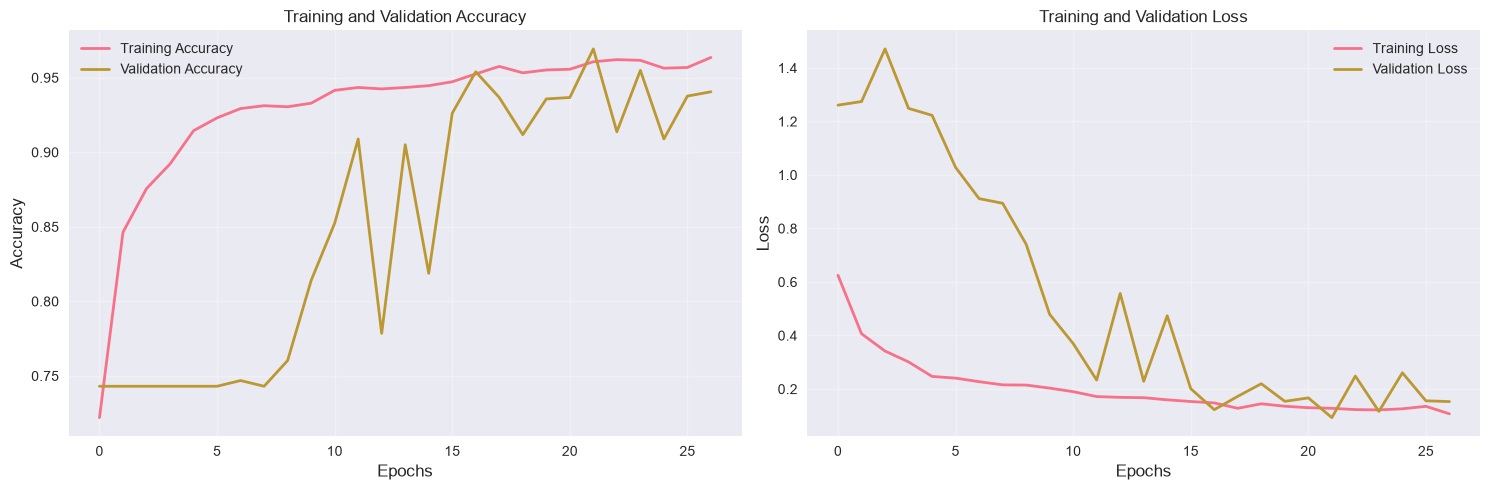

Model final metrics
Accuracy: 0.9636
Validation Accuracy: 0.9406
Loss: 0.1073
Validation Loss: 0.1530


In [30]:
from matplotlib import axes
def plot_training_history(history):
  fig, axes = plt.subplots(1, 2, figsize=(15, 5))

  # Accuracy
  axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
  axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
  axes[0].set_title('Training and Validation Accuracy', fontsize=12)
  axes[0].set_xlabel('Epochs', fontsize=12)
  axes[0].set_ylabel('Accuracy', fontsize=12)
  axes[0].legend()
  axes[0].grid(True, alpha=0.3)

  # Loss
  axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2)
  axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
  axes[1].set_title('Training and Validation Loss', fontsize=12)
  axes[1].set_xlabel('Epochs', fontsize=12)
  axes[1].set_ylabel('Loss', fontsize=12)
  axes[1].legend()
  axes[1].grid(True, alpha=0.3)

  plt.tight_layout()
  plt.show()

  print("Model final metrics")
  print("=" * 50)
  print(f"Accuracy: {history.history['accuracy'][-1]:.4f}")
  print(f"Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")
  print(f"Loss: {history.history['loss'][-1]:.4f}")
  print(f"Validation Loss: {history.history['val_loss'][-1]:.4f}")

plot_training_history(history)

20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 583ms/step
NORMAL = 0
PNEUMONIA = 1


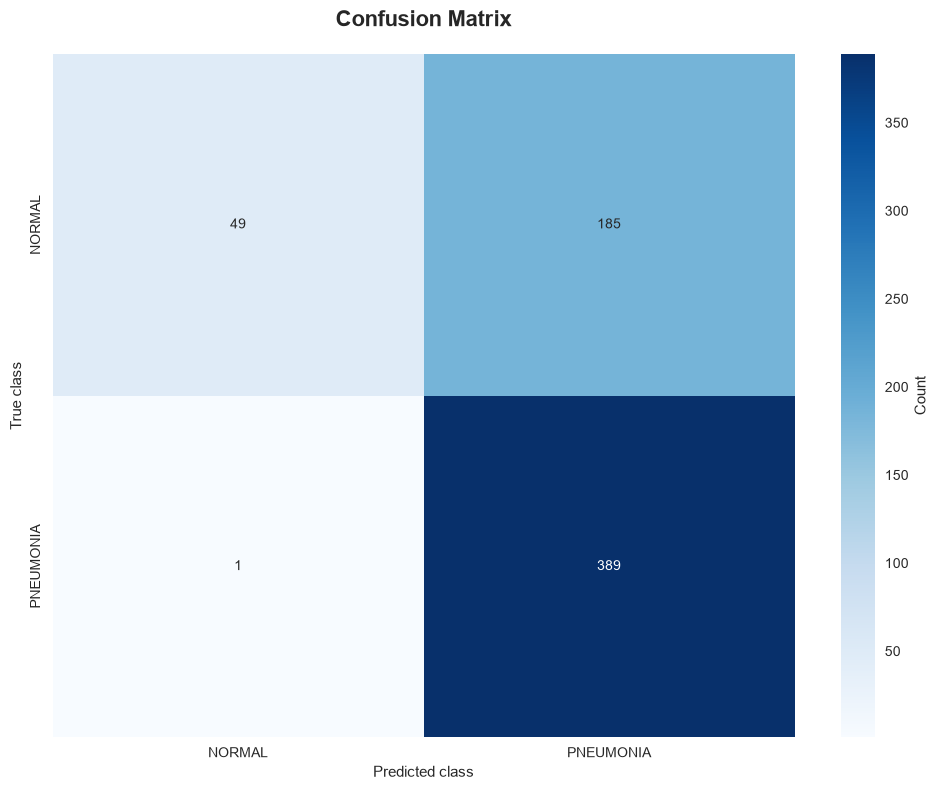

Confusion Matrix:
       Predicted
      NORMAL  PNEUMONIA
True  NORMAL: 49  185
      PNEUMONIA: 1  389
True positives (TP): 389 - true predicted PNEUMONIA
True negatives (TN): 49 - true predicted NORMAL
False positives (FP): 185 - false predicted PNEUMONIA
False negatives (FN): 1 - false predicted NORMAL
Accuracy: 0.7019
Precision NORMAL: 0.9800
Precision PNEUMONIA: 0.6777
Recall NORMAL: 0.2094
Recall PNEUMONIA: 0.9974
F1 score NORMAL: 0.3451
F1 score PNEUMONIA: 0.8071


In [31]:
test_generator.reset()
predictions = model.predict(test_generator)
predicted_classes = (predictions> 0.5).astype(int).flatten()
true_classes = test_generator.classes

class_names = list(test_generator.class_indices.keys())

print(f"{class_names[0]} = 0")
print(f"{class_names[1]} = 1")

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print("       Predicted")
print(f"      {class_names[0]}  {class_names[1]}")
print(f"True  {class_names[0]}: {cm[0][0]}  {cm[0][1]}")
print(f"      {class_names[1]}: {cm[1][0]}  {cm[1][1]}")

TN = cm[0][0]
FP = cm[0][1]
FN = cm[1][0]
TP = cm[1][1]

print(f"True positives (TP): {TP} - true predicted {class_names[1]}")
print(f"True negatives (TN): {TN} - true predicted {class_names[0]}")
print(f"False positives (FP): {FP} - false predicted {class_names[1]}")
print(f"False negatives (FN): {FN} - false predicted {class_names[0]}")

accuracy = accuracy_score(true_classes, predicted_classes)
precision_0 = TN/(TN+FN) if TN+FN > 0 else 0
precision_1 = TP/(TP+FP) if TP+FP > 0 else 0
recall_0 = TN/(TN+FP) if TN+FP > 0 else 0
recall_1 = TP/(TP+FN) if TP+FN > 0 else 0

f1_0 = 2 * (precision_0 * recall_0) / (precision_0 + recall_0) if precision_0 + recall_0 > 0 else 0
f1_1 = 2 * (precision_1 * recall_1) / (precision_1 + recall_1) if precision_1 + recall_1 > 0 else 0

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision {class_names[0]}: {precision_0:.4f}")
print(f"Precision {class_names[1]}: {precision_1:.4f}")
print(f"Recall {class_names[0]}: {recall_0:.4f}")
print(f"Recall {class_names[1]}: {recall_1:.4f}")
print(f"F1 score {class_names[0]}: {f1_0:.4f}")
print(f"F1 score {class_names[1]}: {f1_1:.4f}")